# Kinase-TF Correlated Group Panel


## 0. Imports & paths

In [1]:
import os
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from scipy import stats
import networkx as nx

CORR_METHOD    = "pearson"
CORR_R_THRESH  = 0
CORR_P_THRESH  = 0.05

psites_f  = "/ix/djishnu/Aaron_F/proteomics_proj/Data/phosphoproteomics/TMT_control_centered_log2fc.csv"
desites_f = "/ix/djishnu/Aaron_F/proteomics_proj/Data/phosphoproteomics/significant_phospho_pairwise_ids_and_flanks.csv"

sig_sites_f    = "/ix/djishnu/Aaron_F/proteomics_proj/Data/phosphoproteomics/significant_phospho_pairwise_res.csv"
phospho_data_f = "/ix/djishnu/Aaron_F/proteomics_proj/Data/phosphoproteomics/stat_results_IL6IL10phosphopairwiseBMDMheatmap.csv"
tf1_f = "/ix/djishnu/Aaron_F/proteomics_proj/Results/DEG_motif_enrichment/common_degs_enr/sig_TF_results/out_files/sig_tomtom_TFs_withLabels.csv"
tf2_f = "/ix/djishnu/Aaron_F/proteomics_proj/Results/modisco/out_files/sig_modisco_TFs_withLabels.csv"
tf3_f = "/ix/djishnu/Aaron_F/proteomics_proj/Results/decoupler/out_files/sig_decoupler_TFs_withLabels.csv"

module_assignments_f = "/ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/kinase_module_heatmap/out_files/kinase_module_assignments.csv"
tf_module_summary_f = "/ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/site_module_heatmap/out_files/tf_module_overlap_summary.csv"

kinome_f = "/ix/djishnu/Aaron_F/proteomics_proj/Data/phosphoproteomics/kinome_information.tsv"

out_dir = "/ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/kinase_tf_coexpression"
os.makedirs(out_dir, exist_ok=True)
os.makedirs(f"{out_dir}/figures", exist_ok=True)
os.makedirs(f"{out_dir}/out_files", exist_ok=True)

TOP_N_TF_SITES = 6

## 1. Load modules, TF-module associations, and dynamic (DE) sites

In [2]:
module_df = pd.read_csv(module_assignments_f)
module_ids = sorted(module_df["module"].unique())

tf_module_summary = pd.read_csv(tf_module_summary_f)

desites = pd.read_csv(desites_f)['id'].tolist()

prot_df = pd.read_csv(psites_f)
print(f"Modules: {len(module_ids)}  |  Dynamic sites: {len(desites)}  |  "
      f"Full proteomics table: {prot_df.shape}")

Modules: 12  |  Dynamic sites: 1220  |  Full proteomics table: (21641, 16)


## 2. Canonicalize module kinase names to gene symbols

`module_df["kinase"]` uses kinase_library's short-form names -- map to actual gene symbols before matching against `prot_df["geneSymbol"]`.

In [3]:
kinome = pd.read_csv(kinome_f, sep="\t")
kl_to_gene = dict(zip(kinome['KINASE'].str.upper(), kinome['GENE_NAME'].str.upper()))

module_df['kinase_gene'] = module_df['kinase'].str.upper().map(kl_to_gene)
n_unmapped = module_df['kinase_gene'].isna().sum()
if n_unmapped:
    unmapped_names = sorted(module_df.loc[module_df['kinase_gene'].isna(), 'kinase'].unique())
    print(f"WARNING: {n_unmapped} module kinases had no gene-symbol mapping "
          f"in kinome_information.tsv, falling back to kinase name as-is: {unmapped_names}")
    module_df.loc[module_df['kinase_gene'].isna(), 'kinase_gene'] = (
        module_df.loc[module_df['kinase_gene'].isna(), 'kinase'].str.upper()
    )

print(f"Module kinases: {len(module_df)}  |  Mapped to a gene symbol: {len(module_df) - n_unmapped}")

Module kinases: 83  |  Mapped to a gene symbol: 83


## 3. Rebuild dynamic TF sites (need full `id` to pull raw trajectory values)

In [4]:
sig_sites = pd.read_csv(sig_sites_f)
sig_sites['geneSymbol'] = sig_sites['id'].str.split('_').str[0]
sig_sites['id']         = sig_sites['id'].str.split('_', n=1).str[1]
sig_sites_list          = sig_sites.id.tolist()

phospho_ids = pd.read_csv(phospho_data_f)
phospho_ids['geneSymbol'] = phospho_ids['id'].str.split('_').str[0]
phospho_ids['id']         = phospho_ids['id'].str.split('_', n=1).str[1]
phospho_ids = phospho_ids[["id", "geneSymbol"]]

dyn_sites = phospho_ids.loc[phospho_ids.id.isin(sig_sites_list)].copy().reset_index(drop=True)

tf1_genes = pd.read_csv(tf1_f).loc[lambda d: d.is_expressed, "tf_symbol"].tolist()
tf2_genes = pd.read_csv(tf2_f).loc[lambda d: d.is_expressed, "tf_symbol"].tolist()
tf3_genes = pd.read_csv(tf3_f).loc[lambda d: d.is_expressed, "tf_symbol"].tolist()
tf_genes = list(set(tf1_genes + tf2_genes + tf3_genes))

dyn_tf_sites = dyn_sites.loc[dyn_sites.geneSymbol.isin(tf_genes)].copy().reset_index(drop=True)
dyn_tf_sites["site_label"] = dyn_tf_sites["geneSymbol"] + "_" + dyn_tf_sites["id"].str.split("_").str[1]
dup_mask = dyn_tf_sites["site_label"].duplicated(keep=False)
if dup_mask.any():
    suffix = dyn_tf_sites.groupby("site_label").cumcount().astype(str)
    dyn_tf_sites.loc[dup_mask, "site_label"] += "_dup" + suffix[dup_mask]

site_label_to_id = dict(zip(dyn_tf_sites["site_label"], dyn_tf_sites["id"]))
print(f"Dynamic TF sites resolved: {len(site_label_to_id)}")

Dynamic TF sites resolved: 42


## 4. Trajectory and correlation helpers

In [5]:
time_order = ["0m", "20m", "45m", "90m"]

unstim_cols = [c for c in prot_df.columns if "PBS_0" in c]
il6_cols    = [c for c in prot_df.columns if "IL6" in c]
il10_cols   = [c for c in prot_df.columns if "IL10" in c]

cytokine_cols_map = {"IL6": il6_cols, "IL10": il10_cols}
CYTOKINE_COLOR = {"IL6": "#d62728", "IL10": "#1f77b4"}
x = np.arange(len(time_order))

def single_site_trajectory(row, cytokine_cols):
    vals = []
    for t in time_order:
        time_cols = unstim_cols if t == "0m" else [c for c in cytokine_cols if t.rstrip("m") in c]
        vals.append(row[time_cols].mean())
    return np.array(vals)

def paired_correlation(kinase_row, tf_row):
    """Pooled IL6+IL10 replicate samples, PBS excluded, n=12."""
    cols = il6_cols + il10_cols
    x_vals = kinase_row[cols].astype(float).values
    y_vals = tf_row[cols].astype(float).values
    if CORR_METHOD == "spearman":
        r, p = stats.spearmanr(x_vals, y_vals)
    else:
        r, p = stats.pearsonr(x_vals, y_vals)
    return r, p

def get_markers(n):
    """Distinct marker shapes for up to ~11 entities before repeating."""
    shapes = ['o', '^', 'v', '<', '>', 'p', 'h', '8', '*', 'X', 'P']
    return [shapes[i % len(shapes)] for i in range(n)]

## 5. Discover kinase-TF correlated groups per module

Same connected-component logic as before -- kinases that share a passing TF end up grouped together; an isolated kinase-TF pair forms its own singleton group, even within the same module. This step ONLY discovers groups and records their entities/correlations; no plotting happens here.

In [6]:
prot_df_genes_upper = set(prot_df["geneSymbol"].str.upper())
correlation_results = []
discovered_groups = []      # [{"module": m, "group_idx": i, "kinases": [...], "tfs": [...], "tf_best_r": {...}}]
kinase_row_by_label = {}    # global, across all modules

# Merge modules 5 and 6 into one combined "5_6" pseudo-module for THIS
# discovery step -- same meta-module grouping as the fig3a/tf_site_module
# heatmaps. Kinases from both modules get pooled together, and their
# combined candidate TF sites (top-4 by neg_log10_p across BOTH modules'
# Fisher's exact results, deduped) get used as one shared candidate pool
# -- discovery then runs ONCE for "5_6" instead of separately for 5 and
# separately for 6.
MODULE_MERGE = {5: "5_6", 6: "5_6"}

def display_module(m):
    return MODULE_MERGE.get(m, m)

merged_module_ids = sorted(
    set(display_module(m) for m in module_ids),
    key=lambda d: min(m for m in module_ids if display_module(m) == d),
)

for disp_m in merged_module_ids:
    raw_modules = [m for m in module_ids if display_module(m) == disp_m]

    kinase_genes = set(module_df.loc[module_df["module"].isin(raw_modules), "kinase_gene"])
    module_kinase_sites = prot_df[
        prot_df["geneSymbol"].str.upper().isin(kinase_genes) & prot_df["id"].isin(desites)
    ].copy()

    if module_kinase_sites.empty:
        continue

    module_kinase_sites["site_label"] = (
        module_kinase_sites["geneSymbol"].str.upper() + "_" + module_kinase_sites["id"].str.split("_").str[1]
    )
    dup_mask = module_kinase_sites["site_label"].duplicated(keep=False)
    if dup_mask.any():
        suffix = module_kinase_sites.groupby("site_label").cumcount().astype(str)
        module_kinase_sites.loc[dup_mask, "site_label"] += "_dup" + suffix[dup_mask]

    top_tf_sites = (
        tf_module_summary[tf_module_summary["module"].isin(raw_modules)]
        .sort_values("neg_log10_p", ascending=False)
        .drop_duplicates(subset="site_label")  # a site can appear for both merged modules
        .head(TOP_N_TF_SITES)["site_label"]
        .tolist()
    )

    passing_tfs_by_kinase = {}
    for _, kinase_row in module_kinase_sites.iterrows():
        kinase_label = kinase_row["site_label"]
        kinase_row_by_label[kinase_label] = kinase_row
        for tf_label in top_tf_sites:
            tf_site_id = site_label_to_id.get(tf_label)
            if tf_site_id is None or tf_site_id not in prot_df["id"].values:
                continue
            tf_row = prot_df.loc[prot_df["id"] == tf_site_id].iloc[0]

            r, p = paired_correlation(kinase_row, tf_row)
            passed = (abs(r) >= CORR_R_THRESH) and (p < CORR_P_THRESH)
            correlation_results.append({"module": disp_m, "kinase_site": kinase_label,
                                         "tf_site": tf_label, "r": r, "p_value": p, "passed": passed})
            if passed:
                passing_tfs_by_kinase.setdefault(kinase_label, []).append((tf_label, r, p))

    if not passing_tfs_by_kinase:
        continue

    G = nx.Graph()
    edge_r = {}
    for kinase_label, tf_hits in passing_tfs_by_kinase.items():
        for tf_label, r, p in tf_hits:
            G.add_edge(kinase_label, tf_label)
            edge_r[(kinase_label, tf_label)] = r

    components = sorted(nx.connected_components(G), key=len, reverse=True)
    for comp_idx, component in enumerate(components, start=1):
        kinases_in_plot = [n for n in component if n in passing_tfs_by_kinase]
        seen_tfs = [n for n in component if n not in passing_tfs_by_kinase]
        tf_best_r = {}
        for tf_label in seen_tfs:
            rs = [edge_r[(k, tf_label)] for k in kinases_in_plot if (k, tf_label) in edge_r]
            tf_best_r[tf_label] = max(rs, key=abs)

        discovered_groups.append({
            "module": disp_m, "group_idx": comp_idx,
            "kinases": kinases_in_plot, "tfs": seen_tfs, "tf_best_r": tf_best_r,
        })

corr_df = pd.DataFrame(correlation_results)
corr_df.to_csv(f"{out_dir}/out_files/kinase_tf_pair_correlations.csv", index=False)

print(f"Discovered groups by module:")
for grp in discovered_groups:
    print(f"  Module {grp['module']}, group {grp['group_idx']}: "
          f"kinases={grp['kinases']}, tfs={grp['tfs']}")

Discovered groups by module:
  Module 1, group 1: kinases=['MTOR_S2450s', 'MTOR_S2478sS2481s'], tfs=['Nfatc1_T761tS766s', 'Nfatc2_S99s', 'Nfatc2_S739s']
  Module 1, group 2: kinases=['CDK13_S260s'], tfs=['Erf_T529t', 'Foxk1_T233tS243s']
  Module 2, group 1: kinases=['SRPK2_S490s', 'SRPK2_S491sT492t', 'CLK1_S101s'], tfs=['Etv3_S245sS250s', 'Nfil3_S301s', 'Arntl_T44t', 'Etv3_S29s']
  Module 5_6, group 1: kinases=['TLK1_S134s', 'TLK2_S73s'], tfs=['Tfeb_T157t', 'Arid3a_S127sT132t', 'Tcf7l2_S35s', 'Creb1_S142s']
  Module 5_6, group 2: kinases=['NEK9_S834s'], tfs=['Etv3_S29s']
  Module 7, group 1: kinases=['AAK1_S676s'], tfs=['Foxo3_T306t', 'Tfeb_S392s', 'Nfatc1_T761tS766s']
  Module 9, group 1: kinases=['PKN2_T121t'], tfs=['Erf_T529t', 'Arntl_T44t']
  Module 10, group 1: kinases=['PDPK1_S38s'], tfs=['Tfeb_S392s', 'Nfatc1_T761tS766s', 'Nfatc2_S99s', 'Creb1_S142s']
  Module 11, group 1: kinases=['MAPKAPK2_T9tS16s'], tfs=['Lrrfip1_S284s', 'Foxo3_S252s', 'Foxo4_S197s']


## 5b. Diagnostic -- trace a specific TF site through all 3 gates


In [7]:
# ---- DIAGNOSTIC: why doesn't Arid3a end up in any group? ----
DIAG_TF_NAME = "ARID3A"

print(f"\n{'='*70}\nDiagnostic: {DIAG_TF_NAME}\n{'='*70}")

# Gate 1 -- did it even make it into dyn_tf_sites (dynamic + expressed TF + Ser/Thr)?
gate1 = dyn_tf_sites[dyn_tf_sites["geneSymbol"].str.upper() == DIAG_TF_NAME]
print(f"\nGate 1 -- dyn_tf_sites rows (dynamic + expressed TF gene):")
print(gate1[["id", "geneSymbol", "site_label"]].to_string(index=False) if len(gate1) else "  NONE -- dropped before scoring")

# Gate 2 -- did it get a module enrichment score, and rank in ANY module's top-4?
gate2_all = tf_module_summary[tf_module_summary["site_label"].str.upper().str.contains(DIAG_TF_NAME)]
print(f"\nGate 2 -- tf_module_summary rows (all modules, not just top-4):")
print(gate2_all.sort_values(["module", "neg_log10_p"], ascending=[True, False]).to_string(index=False)
      if len(gate2_all) else "  NONE -- no enrichment score computed at all for this site")

if len(gate2_all):
    print(f"\nGate 2b -- rank within each module (1-indexed, by neg_log10_p, descending):")
    for m in sorted(gate2_all["module"].unique()):
        mod_sub = tf_module_summary[tf_module_summary["module"] == m].sort_values("neg_log10_p", ascending=False).reset_index(drop=True)
        this_site_rows = mod_sub[mod_sub["site_label"].str.upper().str.contains(DIAG_TF_NAME)]
        for _, row in this_site_rows.iterrows():
            rank = mod_sub[mod_sub["site_label"] == row["site_label"]].index[0] + 1
            made_top4 = "YES" if rank <= TOP_N_TF_SITES else "no"
            print(f"  Module {m}: {row['site_label']} rank={rank} (top-{TOP_N_TF_SITES} candidate: {made_top4})")

# Gate 3 -- if it was ever tested for correlation, did anything pass?
gate3 = corr_df[corr_df["tf_site"].str.upper().str.contains(DIAG_TF_NAME)]
print(f"\nGate 3 -- corr_df rows (every correlation test actually run against this site):")
print(gate3.to_string(index=False) if len(gate3) else "  NONE -- never tested (didn't make any module's top-4 candidate pool)")

if len(gate3):
    n_passed = gate3["passed"].sum()
    print(f"\n  {n_passed} / {len(gate3)} correlation tests passed (p < {CORR_P_THRESH})")

# ---- follow-up: for each module the TF site DID qualify for (top-4),
# was it actually tested? Distinguishes two different skip points that
# look identical from corr_df alone:
#   (A) module_kinase_sites empty -> whole module skipped, nobody tested
#   (B) this specific tf_site_id missing from prot_df -- only this TF
#       skipped, kinases in that module still got tested against others
print(f"\nGate 2c -- for each module where it qualified as top-{TOP_N_TF_SITES}, was it actually tested?")
qualifying_modules = []
if len(gate2_all):
    for m in sorted(gate2_all["module"].unique()):
        mod_sub = tf_module_summary[tf_module_summary["module"] == m].sort_values("neg_log10_p", ascending=False).reset_index(drop=True)
        this_site_rows = mod_sub[mod_sub["site_label"].str.upper().str.contains(DIAG_TF_NAME)]
        for _, row in this_site_rows.iterrows():
            rank = mod_sub[mod_sub["site_label"] == row["site_label"]].index[0] + 1
            if rank <= TOP_N_TF_SITES:
                qualifying_modules.append((m, row["site_label"]))

for m, site_lbl in qualifying_modules:
    disp_m = display_module(m)
    raw_modules_for_disp = [mm for mm in module_ids if display_module(mm) == disp_m]
    kinase_genes_check = set(module_df.loc[module_df["module"].isin(raw_modules_for_disp), "kinase_gene"])
    module_kinase_sites_check = prot_df[
        prot_df["geneSymbol"].str.upper().isin(kinase_genes_check) & prot_df["id"].isin(desites)
    ]
    tf_id_check = site_label_to_id.get(site_lbl)
    tf_id_found = tf_id_check in prot_df["id"].values if tf_id_check is not None else False

    if module_kinase_sites_check.empty:
        reason = "(A) module_kinase_sites EMPTY -- entire module skipped, no dynamic kinase phosphosites at all"
    elif not tf_id_found:
        reason = "(B) tf_site_id not found in prot_df -- only this TF's lookup failed"
    else:
        reason = "should have been tested -- check corr_df directly for this module"

    tested_in_module = len(corr_df[(corr_df["module"] == disp_m) & (corr_df["tf_site"] == site_lbl)]) > 0
    print(f"  Module {m} (-> display {disp_m}): kinase_sites_in_module={len(module_kinase_sites_check)}, "
          f"tf_id_found_in_prot_df={tf_id_found}, actually_tested={tested_in_module}")
    if not tested_in_module:
        print(f"    -> {reason}")

# ---- follow-up: for merged modules ("5_6" etc), check the COMBINED-pool
# rank directly -- did merging modules 5 and 6 into one pool bump this
# site out of the top-4, even though it individually qualified in EITHER
# module alone? Same construction as the real discovery loop's top_tf_sites.
print(f"\nGate 2d -- combined-pool rank for merged modules")
all_display_modules = set(display_module(m) for m in module_ids)
for disp_m in sorted(all_display_modules, key=lambda d: min(m for m in module_ids if display_module(m) == d)):
    raw_modules_for_disp = [mm for mm in module_ids if display_module(mm) == disp_m]
    if len(raw_modules_for_disp) < 2:
        continue  # only relevant for actually-merged groups

    combined_pool = (
        tf_module_summary[tf_module_summary["module"].isin(raw_modules_for_disp)]
        .sort_values("neg_log10_p", ascending=False)
        .drop_duplicates(subset="site_label")
        .reset_index(drop=True)
    )
    this_site = combined_pool[combined_pool["site_label"].str.upper().str.contains(DIAG_TF_NAME)]
    if len(this_site) == 0:
        continue

    rank_in_pool = this_site.index[0] + 1
    made_combined_top4 = rank_in_pool <= TOP_N_TF_SITES
    print(f"  Display module {disp_m} (raw modules {raw_modules_for_disp}): "
          f"combined-pool rank={rank_in_pool}, made top-{TOP_N_TF_SITES}: {made_combined_top4}")
    print(f"    Top {TOP_N_TF_SITES} that won the slots instead:")
    print(combined_pool.head(TOP_N_TF_SITES)[["site_label", "module", "neg_log10_p"]].to_string(index=False))


Diagnostic: ARID3A

Gate 1 -- dyn_tf_sites rows (dynamic + expressed TF gene):
                           id geneSymbol        site_label
Q62431_S127sT132t_2_2_127_132     Arid3a Arid3a_S127sT132t

Gate 2 -- tf_module_summary rows (all modules, not just top-4):
       site_label  module  n_candidates_in_module  n_candidates_total  module_size  odds_ratio  p_value  neg_log10_p
Arid3a_S127sT132t       1                       0                  11           17    0.000000 1.000000    -0.000000
Arid3a_S127sT132t       2                       0                  11           10    0.000000 1.000000    -0.000000
Arid3a_S127sT132t       3                       5                  11            6   59.166667 0.000089     4.048891
Arid3a_S127sT132t       4                       2                  11            4    7.777778 0.083146     1.080161
Arid3a_S127sT132t       5                       2                  11            4    7.777778 0.083146     1.080161
Arid3a_S127sT132t       6          

## 6. Group-plotting function

Draws one group onto a given `ax` (marker=site identity, open=kinase/closed=TF, dashed=kinase/solid=TF, color=cytokine) -- refactored to take explicit kinase/TF label lists instead of always drawing a whole discovered group, so panels can show a hand-filtered subset.

In [8]:
def plot_group_on_ax(ax, kinases, tfs, tf_r_lookup, title):
    entities = kinases + tfs
    markers = get_markers(len(entities))
    entity_marker = dict(zip(entities, markers))

    # Markers much larger relative to line width, and drawn with zorder=3 so
    # they render ON TOP of the connecting lines -- otherwise a thick line
    # crossing through a marker can visually swallow it once the whole
    # figure is scaled down (e.g. shrunk in Illustrator).
    MARKERSIZE = 18
    MARKEREDGEWIDTH = 1.2
    LINEWIDTH = 1.2

    for cytokine, cytokine_cols in cytokine_cols_map.items():
        color = CYTOKINE_COLOR[cytokine]

        for kinase_label in kinases:
            kinase_row = kinase_row_by_label[kinase_label]
            traj = single_site_trajectory(kinase_row, cytokine_cols)
            ax.plot(x, traj, linestyle="--", linewidth=LINEWIDTH, color=color, zorder=1)
            ax.plot(x, traj, marker=entity_marker[kinase_label], markersize=MARKERSIZE,
                    linestyle="none", markerfacecolor="none", markeredgecolor=color,
                    markeredgewidth=MARKEREDGEWIDTH, zorder=3)

        for tf_label in tfs:
            tf_site_id = site_label_to_id.get(tf_label)
            tf_row = prot_df.loc[prot_df["id"] == tf_site_id].iloc[0]
            traj = single_site_trajectory(tf_row, cytokine_cols)
            ax.plot(x, traj, linestyle="-", linewidth=LINEWIDTH, color=color, zorder=1)
            ax.plot(x, traj, marker=entity_marker[tf_label], markersize=MARKERSIZE,
                    linestyle="none", markerfacecolor=color, markeredgecolor=color,
                    markeredgewidth=MARKEREDGEWIDTH, zorder=3)

    entity_handles = [
        plt.Line2D([0], [0], color="black", linestyle="--" if e in kinases else "-",
                   marker=entity_marker[e], markersize=MARKERSIZE,
                   markerfacecolor="none" if e in kinases else "black",
                   markeredgecolor="black", markeredgewidth=MARKEREDGEWIDTH,
                   label=f"{e}" + (" (kinase)" if e in kinases else " (TF)"))
        for e in entities
    ]
    cytokine_handles = [
        plt.Line2D([0], [0], color=CYTOKINE_COLOR[c], linewidth=2, label=c)
        for c in cytokine_cols_map
    ]
    ax.legend(handles=entity_handles + cytokine_handles, fontsize=6,
              loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)

    ax.set_xticks(x)
    ax.set_xticklabels(time_order)
    ax.set_xlabel("Time", fontsize=8)
    ax.set_ylabel("Phosphorylation (log2 FC)", fontsize=8)
    ax.set_title(title, fontsize=8.5)
    ax.tick_params(labelsize=7)

## 6b. Supplement panel -- every discovered group, unfiltered

Every group discovered in Section 5, exactly as found (Module 2's group here still includes every TF it correlated with, not just Etv3 -- the filtering down to SRPK2/Etv3 only happens in the final panel below).

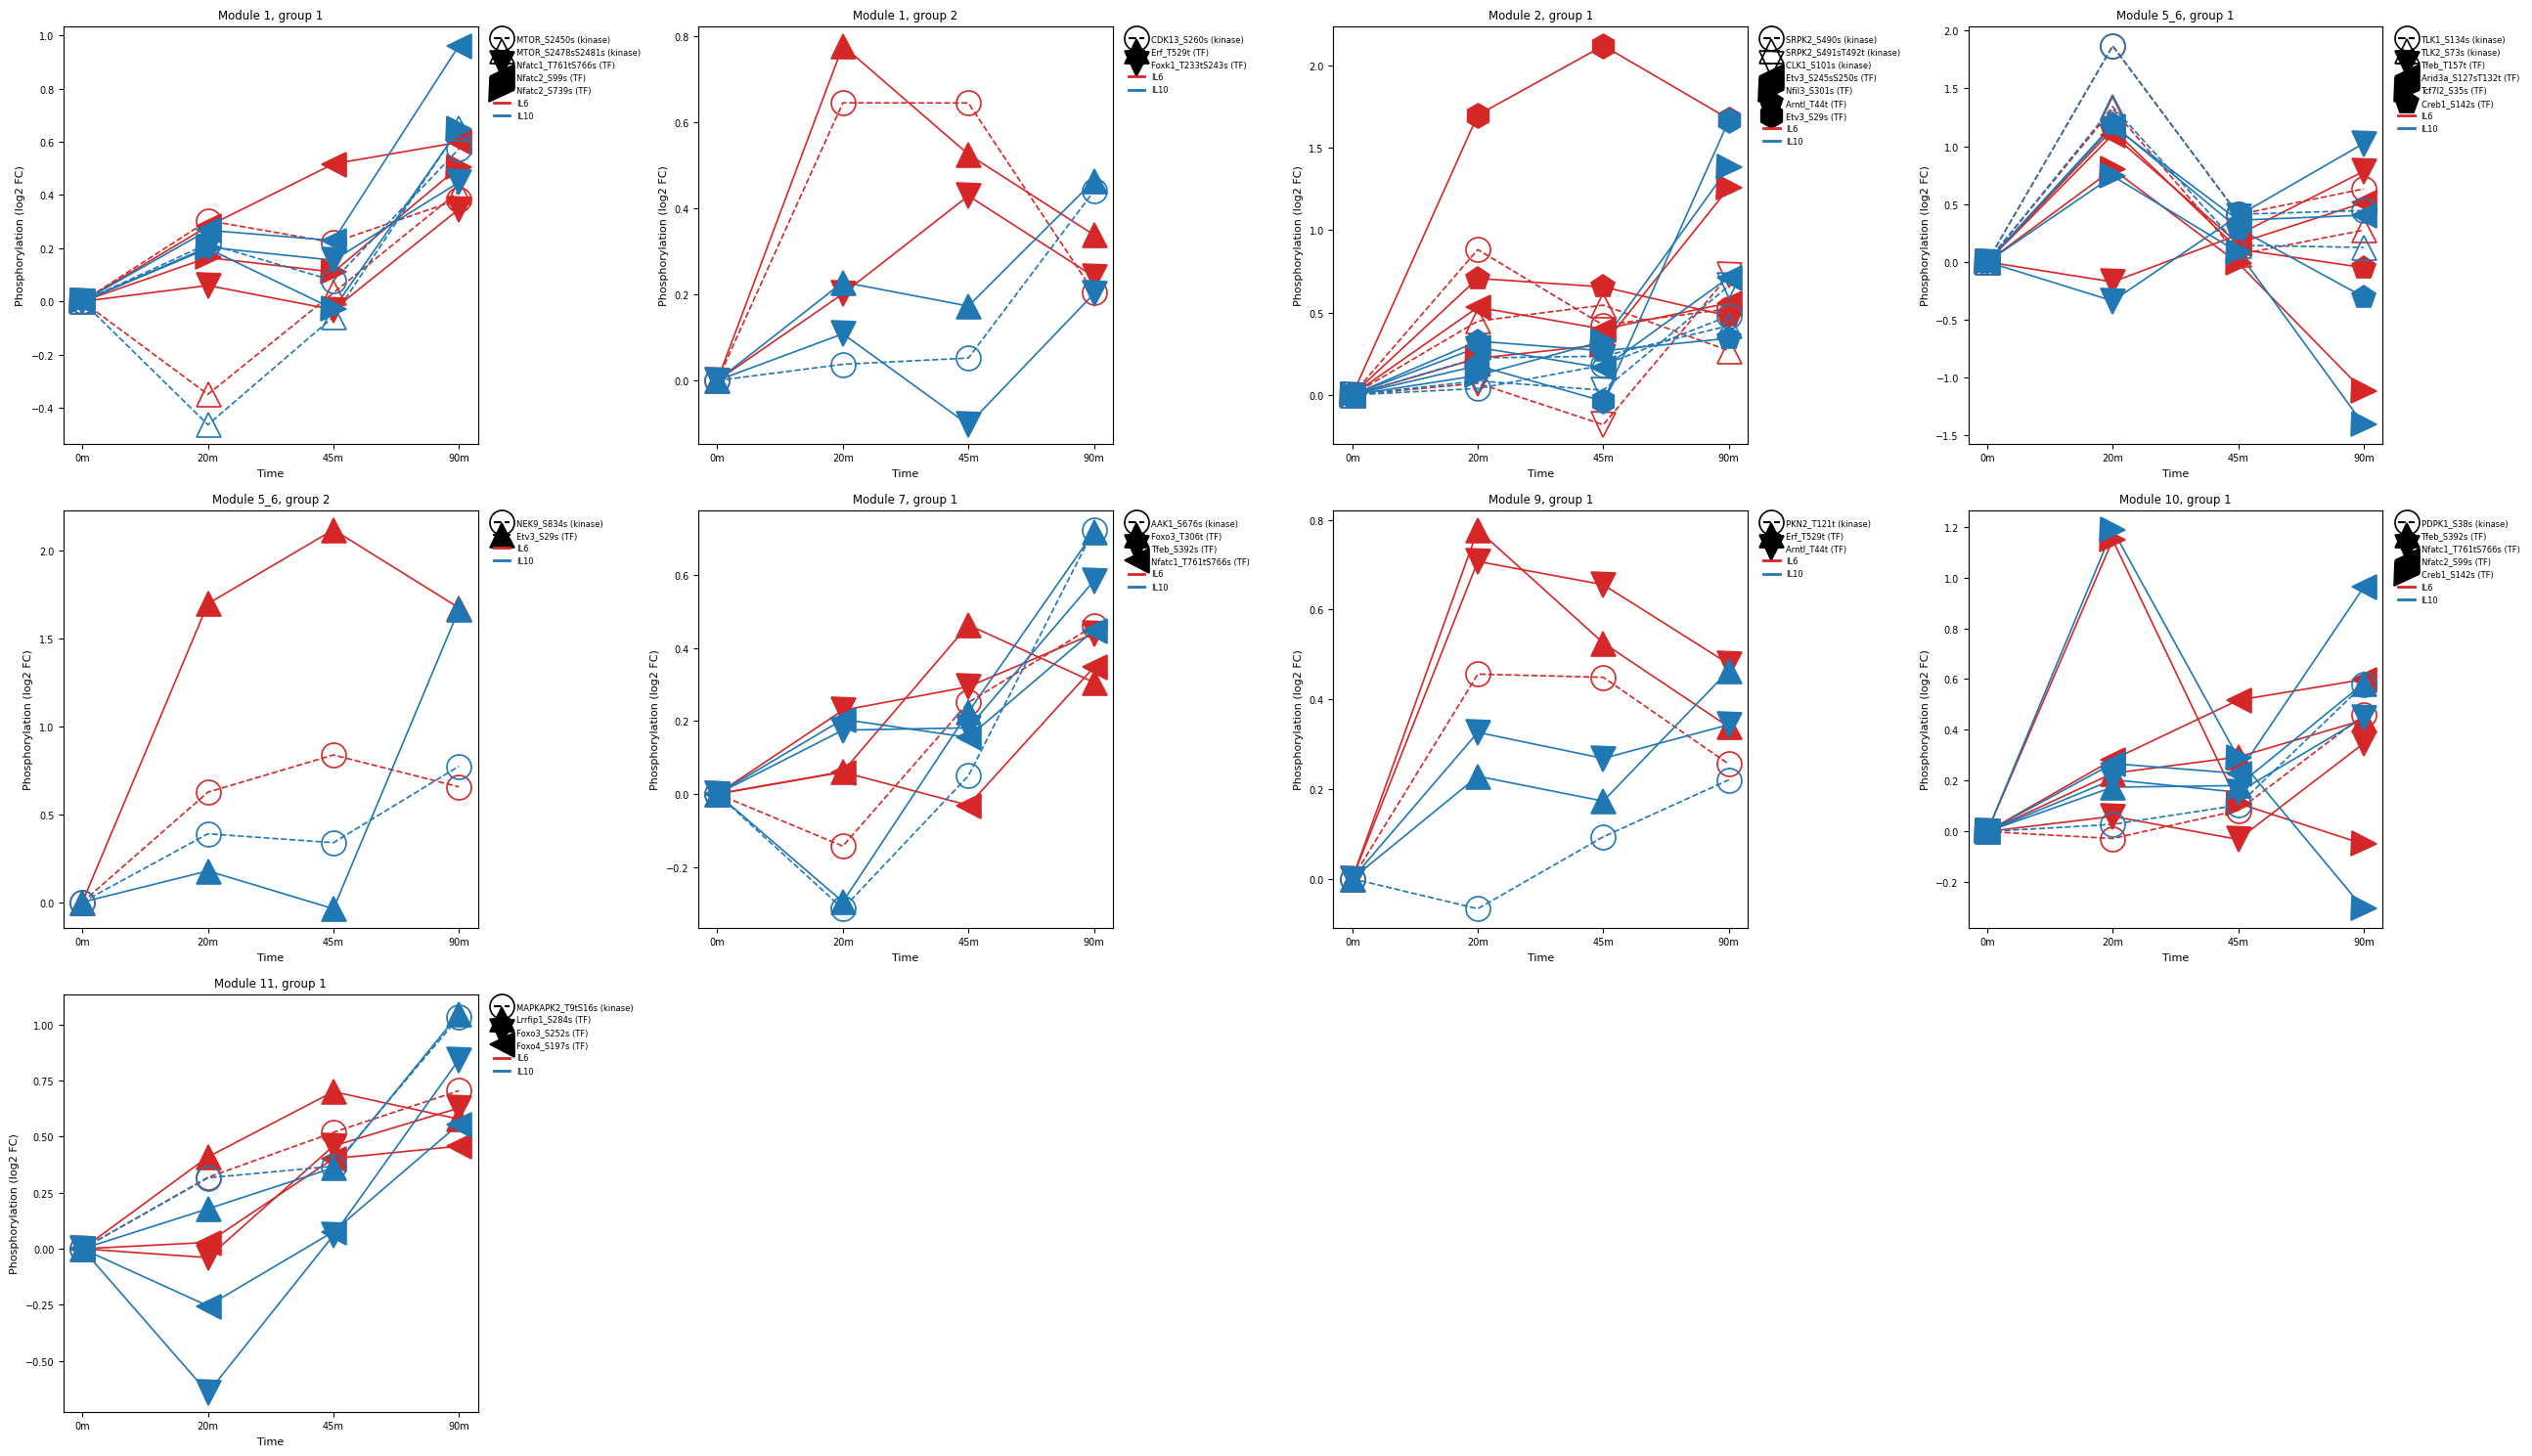

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/kinase_tf_coexpression/figures/fig3d_all_groups_panel_full.png  (9 groups)
Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/kinase_tf_coexpression/figures/fig3d_all_groups_panel_full.svg


In [9]:
n_groups = len(discovered_groups)
ncols = 4
nrows = int(np.ceil(n_groups / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(6.5 * ncols, 5 * nrows))
axes = axes.flatten()

for ax, grp in zip(axes, discovered_groups):
    title = f"Module {grp['module']}, group {grp['group_idx']}"
    plot_group_on_ax(ax, grp["kinases"], grp["tfs"], grp["tf_best_r"], title)

for j in range(len(discovered_groups), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()

png_out_supp = f"{out_dir}/figures/fig3d_all_groups_panel_full.png"
svg_out_supp = f"{out_dir}/figures/fig3d_all_groups_panel_full.svg"
plt.savefig(png_out_supp, dpi=300, bbox_inches="tight")
plt.savefig(svg_out_supp, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved: {png_out_supp}  ({n_groups} groups)")
print(f"Saved: {svg_out_supp}")

## 7. Fig3D final panels -- 4 selected groups, saved INDIVIDUALLY

- Module 1, group 2 only (group 1 dropped)
- Module 2: SRPK2 kinase site(s) + Etv3 TF site only
- Module 5_6, Module 7 (Module 10 dropped)

Each panel is saved as its own separate PNG + SVG at full single-axes size, rather than assembled into one combined grid figure -- shrinking a combined multi-panel image in Illustrator was making the open/closed marker distinction hard to see. Arrange these 4 individual figures into a panel directly in Illustrator instead.

Module 5_6 has 2 groups after merging:
  group_idx=1: kinases=['TLK1_S134s', 'TLK2_S73s'], tfs=['Tfeb_T157t', 'Arid3a_S127sT132t', 'Tcf7l2_S35s', 'Creb1_S142s']
  group_idx=2: kinases=['NEK9_S834s'], tfs=['Etv3_S29s']
Module 2 filtered down to: kinases=['SRPK2_S490s', 'SRPK2_S491sT492t'], tfs=['Etv3_S245sS250s', 'Etv3_S29s']


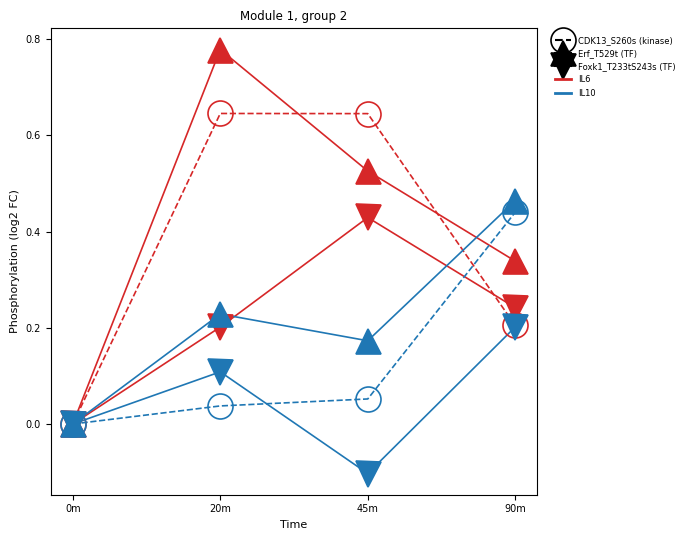

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/kinase_tf_coexpression/figures/fig3d_final_module1_group2.png
Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/kinase_tf_coexpression/figures/fig3d_final_module1_group2.svg


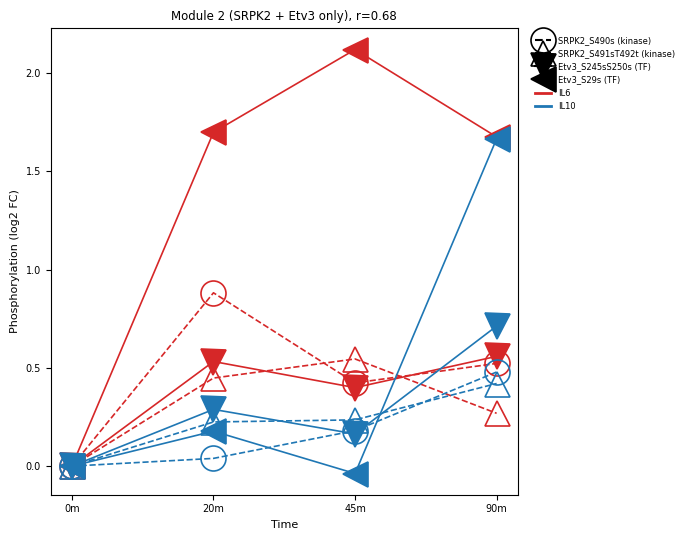

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/kinase_tf_coexpression/figures/fig3d_final_module2_srpk2_etv3.png
Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/kinase_tf_coexpression/figures/fig3d_final_module2_srpk2_etv3.svg


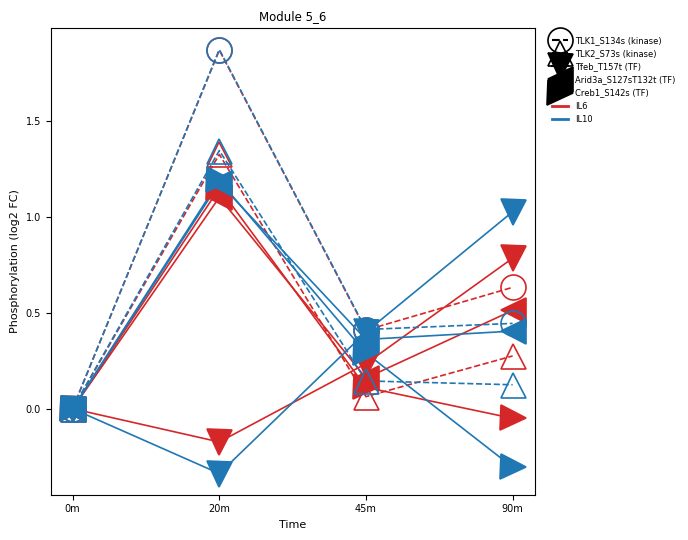

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/kinase_tf_coexpression/figures/fig3d_final_module5_6.png
Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/kinase_tf_coexpression/figures/fig3d_final_module5_6.svg


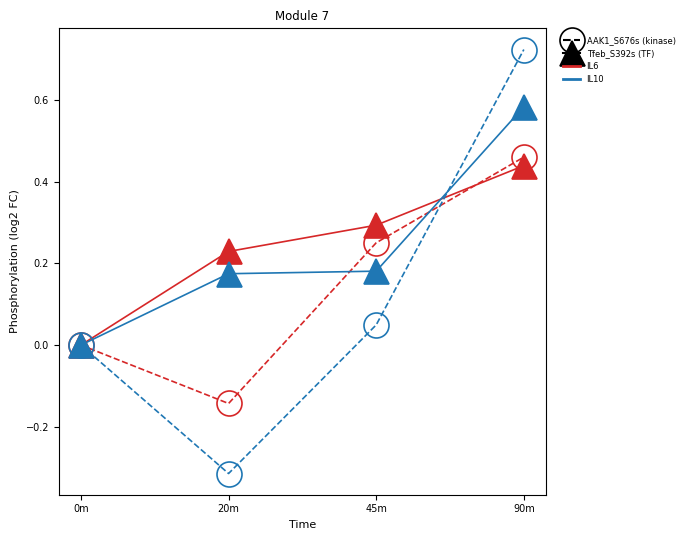

Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/kinase_tf_coexpression/figures/fig3d_final_module7.png
Saved: /ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig2/kinase_tf_coexpression/figures/fig3d_final_module7.svg


In [10]:
def groups_for_module(m):
    return [g for g in discovered_groups if g["module"] == m]

def group_by_module_and_idx(m, idx):
    matches = [g for g in discovered_groups if g["module"] == m and g["group_idx"] == idx]
    assert len(matches) == 1, f"Expected exactly 1 group for module={m}, group_idx={idx}, found {len(matches)}"
    return matches[0]

module1_groups = groups_for_module(1)
assert len(module1_groups) == 2, f"Expected 2 groups for Module 1, found {len(module1_groups)}"

grps7 = groups_for_module(7)
assert len(grps7) == 1, f"Expected exactly 1 group for Module 7, found {len(grps7)}: {grps7}"

# Module 5_6 now has 2 groups after merging -- print both so you can see
# which one you want. group_idx=1 is the larger one (includes Arid3a).
grps_5_6 = groups_for_module("5_6")
print(f"Module 5_6 has {len(grps_5_6)} groups after merging:")
for g in grps_5_6:
    print(f"  group_idx={g['group_idx']}: kinases={g['kinases']}, tfs={g['tfs']}")

module2_groups = groups_for_module(2)
module2_all_kinases = [k for g in module2_groups for k in g["kinases"]]
module2_all_tfs = [t for g in module2_groups for t in g["tfs"]]

srpk2_kinases = [k for k in module2_all_kinases if k.upper().startswith("SRPK2")]
etv3_tfs = [t for t in module2_all_tfs if t.upper().startswith("ETV3")]
print(f"Module 2 filtered down to: kinases={srpk2_kinases}, tfs={etv3_tfs}")

module2_r = corr_df[
    (corr_df["module"] == 2) & (corr_df["kinase_site"].isin(srpk2_kinases)) &
    (corr_df["tf_site"].isin(etv3_tfs))
]["r"].abs().max()

# using group_idx=1 for Module 5_6 -- change to 2 if you want the
# NEK9/Etv3 pair instead
module5_6_group = group_by_module_and_idx("5_6", 1)

# --- Panel 3: drop Tcf7l2_S35s from Module 5_6's TFs ---
module5_6_tfs_filtered = [t for t in module5_6_group["tfs"] if t != "Tcf7l2_S35s"]
module5_6_r_filtered = {k: v for k, v in module5_6_group["tf_best_r"].items() if k != "Tcf7l2_S35s"}

# --- Panel 4: drop Nfatc1_T761tS766s and Foxo3_T306t from Module 7's TFs ---
module7_drop = {"Nfatc1_T761tS766s", "Foxo3_T306t"}
module7_tfs_filtered = [t for t in grps7[0]["tfs"] if t not in module7_drop]
module7_r_filtered = {k: v for k, v in grps7[0]["tf_best_r"].items() if k not in module7_drop}

panels = [
    {"kinases": module1_groups[1]["kinases"], "tfs": module1_groups[1]["tfs"],
     "tf_best_r": module1_groups[1]["tf_best_r"],
     "title": "Module 1, group 2", "name": "module1_group2"},
    {"kinases": srpk2_kinases, "tfs": etv3_tfs, "tf_best_r": {},
     "title": f"Module 2 (SRPK2 + Etv3 only), r={module2_r:.2f}", "name": "module2_srpk2_etv3"},
    {"kinases": module5_6_group["kinases"], "tfs": module5_6_tfs_filtered,
     "tf_best_r": module5_6_r_filtered, "title": "Module 5_6", "name": "module5_6"},
    {"kinases": grps7[0]["kinases"], "tfs": module7_tfs_filtered,
     "tf_best_r": module7_r_filtered, "title": "Module 7", "name": "module7"},
]

for panel in panels:
    fig, ax = plt.subplots(figsize=(7, 5.5))
    plot_group_on_ax(ax, panel["kinases"], panel["tfs"], panel["tf_best_r"], panel["title"])
    plt.tight_layout()

    png_out = f"{out_dir}/figures/fig3d_final_{panel['name']}.png"
    svg_out = f"{out_dir}/figures/fig3d_final_{panel['name']}.svg"
    plt.savefig(png_out, dpi=300, bbox_inches="tight")
    plt.savefig(svg_out, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"Saved: {png_out}")
    print(f"Saved: {svg_out}")